# HW05 (e) - Standalone second stage

Preserve W/L = 5 um / 50 nm, 1-V gate bias, 1.5-mA source current, 100-fF source bypass and a 150-fF output load. Tune L2, then compute gain and IIP3. The original 10-mVpk-per-tone setting is preserved.

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import math
import cmath
WORK = GENERATED / "e_stage_tran.scs"
RESULTS = SIMULATION / "e"
F1, F2 = 5.79e9, 5.81e9
IM31, IM32 = 2*F1-F2, 2*F2-F1
ATONE = 10e-3  # Original completed run used 10 mVpk/tone.
TSTOP, WINDOW_START = 160e-9, 60e-9
MAXSTEP, STROBE = 3e-12, 5e-12


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def run():
    return run_spectre(WORK, RESULTS)

def tank(l_nh):
    l_h = l_nh * 1e-9
    rp = Q * 2 * math.pi * F0 * l_h
    cp = 10e-15 * l_nh
    return l_h, rp, cp

def mos_line():
    return (
        "M2 (Vout Vin S 0) NMOS_VTH w=5u l=50n "
        "as=9.45e-15 ad=9.45e-15 ps=300n pd=300n "
        "ld=105n ls=105n m=1"
    )

def write_ac(l_nh):
    l_h, rp, cp = tank(l_nh)
    write_netlist(WORK, f'''simulator lang=spectre
global 0
include "{MODEL}"

VDD (vdd 0) vsource dc=1
VG  (Vin 0) vsource dc=1 mag=0
IB  (S 0) isource dc=1.5m
CS  (S 0) capacitor c=100f

{mos_line()}

L2    (vdd Vout) inductor l={l_h:.12g}
RP2   (vdd Vout) resistor r={rp:.12g}
CP2A  (vdd 0) capacitor c={cp:.12g}
CP2B  (Vout 0) capacitor c={cp:.12g}
CLOAD (Vout 0) capacitor c=150f

ITEST (Vout 0) isource dc=0 type=sine mag=1 phase=0

simulatorOptions options temp=27 tnom=27 gmin=1e-12 reltol=1e-4
ac ac start=4G stop=8G lin=401
save Vout Vin S
saveOptions options save=allpub
''')

def write_tran(l_nh):
    l_h, rp, cp = tank(l_nh)
    write_netlist(WORK, f'''simulator lang=spectre
global 0
include "{MODEL}"

VDD (vdd 0) vsource dc=1
VBIAS (vbias 0) vsource dc=1
VT1 (tone1 vbias) vsource type=sine dc=0 ampl={ATONE:.12g} freq={F1:.12g}
VT2 (Vin tone1) vsource type=sine dc=0 ampl={ATONE:.12g} freq={F2:.12g}

IB  (S 0) isource dc=1.5m
CS  (S 0) capacitor c=100f

{mos_line()}

L2    (vdd Vout) inductor l={l_h:.12g}
RP2   (vdd Vout) resistor r={rp:.12g}
CP2A  (vdd 0) capacitor c={cp:.12g}
CP2B  (Vout 0) capacitor c={cp:.12g}
CLOAD (Vout 0) capacitor c=150f

simulatorOptions options temp=27 tnom=27 gmin=1e-12 reltol=1e-4
tran tran stop={TSTOP:.12g} maxstep={MAXSTEP:.12g} strobeperiod={STROBE:.12g}
save Vout Vin S
saveOptions options save=allpub
''')

def read_ac():
    from psf import read_ascii
    freq, traces = read_ascii(find_result(RESULTS, "ac"), "freq", ["Vout"], complex_values=True)
    return freq.tolist(), traces["Vout"].tolist()


def resonance(l_nh):
    write_ac(l_nh)
    run()
    f, v = read_ac()
    mag2 = [z.real*z.real + z.imag*z.imag for z in v]
    i = max(range(len(mag2)), key=mag2.__getitem__)
    fres = f[i]
    if 0 < i < len(f)-1:
        ym, y0, yp = mag2[i-1], mag2[i], mag2[i+1]
        den = ym - 2*y0 + yp
        if den != 0:
            d = 0.5*(ym-yp)/den
            if abs(d) <= 1:
                fres = f[i] + d * 0.5*(f[i+1]-f[i-1])
    print(f"RES L2={l_nh:.6f} nH -> {fres/1e9:.7f} GHz")
    return fres

def tune_l():
    lo, hi = 0.5, 10.0
    flo, fhi = resonance(lo), resonance(hi)
    if not (flo >= F0 and fhi <= F0):
        raise RuntimeError("Could not bracket L2 resonance")
    best = None
    for _ in range(14):
        mid = 0.5*(lo+hi)
        fm = resonance(mid)
        err = abs(fm-F0)
        if best is None or err < best[0]:
            best = (err, mid, fm)
        if err <= 2e6:
            break
        if fm > F0:
            lo = mid
        else:
            hi = mid
    return best[1], best[2]

def read_tran():
    from psf import read_ascii
    names = ['Vout', 'Vin']
    t, traces = read_ascii(find_result(RESULTS, "tran"), "time", names)
    if len(t) < 100:
        raise ValueError("Not enough transient samples")
    return (t.tolist(), *(traces[name].tolist() for name in names))


def tone_amp(t, y, f):
    pts = [(ti, yi) for ti, yi in zip(t, y) if WINDOW_START <= ti < TSTOP]
    mean = sum(yi for _, yi in pts) / len(pts)
    w = 2 * math.pi * f
    z = sum((yi-mean) * cmath.exp(-1j*w*ti) for ti, yi in pts)
    return 2 * abs(z) / len(pts)

def gmean(a,b):
    return math.sqrt(max(a,1e-300)*max(b,1e-300))


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("e", {"e": {name: globals()[name] for name in ['F1', 'F2', 'ATONE', 'TSTOP', 'WINDOW_START', 'MAXSTEP', 'STROBE']}})

    show_part("e")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    meta = load_meta()

    print("HW5(e): tune L2 and measure second-stage gain/IIP3")
    l_nh, fres = tune_l()
    _, rp, cp = tank(l_nh)

    write_tran(l_nh)
    run()
    t, vo, vi = read_tran()

    of1, of2 = tone_amp(t,vo,F1), tone_amp(t,vo,F2)
    oi1, oi2 = tone_amp(t,vo,IM31), tone_amp(t,vo,IM32)
    if1, if2 = tone_amp(t,vi,F1), tone_amp(t,vi,F2)

    af = gmean(of1,of2)
    aim = gmean(oi1,oi2)
    ain = gmean(if1,if2)

    delta_db = 20*math.log10(af/aim)
    gain_db = 20*math.log10(af/ain)
    ain_dbv = 20*math.log10(ain)
    iip3_dbv = ain_dbv + delta_db/2
    iip3_vpk = 10**(iip3_dbv/20)

    meta["parts"]["e"] = {
        "status": "complete",
        "completed_utc": now(),
        "depends_on": [],
        "inputs": {
            "device": "NMOS_VTH",
            "W_um": 5.0,
            "L_um": 0.05,
            "source_current_mA": 1.5,
            "source_bypass_fF": 100.0,
            "output_load_fF": 150.0,
            "gate_bias_V": 1.0,
            "f1_Hz": F1,
            "f2_Hz": F2,
            "tone_Vpk_each": ATONE,
        },
        "outputs": {
            "L2_nH": l_nh,
            "Rp_ohm": rp,
            "Cp_each_fF": cp*1e15,
            "fres_Hz": fres,
            "Vout_fund_Vpk_geomean": af,
            "Vout_IM3_Vpk_geomean": aim,
            "fund_minus_IM3_dB": delta_db,
            "voltage_gain_dB": gain_db,
            "IIP3_dBV_peak": iip3_dbv,
            "IIP3_Vpk": iip3_vpk,
        },
    }
    save_meta(meta)

    print("\n===== HW5(e) RESULT =====")
    print(f"L2   = {l_nh:.6f} nH")
    print(f"Rp   = {rp:.3f} ohm")
    print(f"Cp   = {cp*1e15:.3f} fF each")
    print(f"fres = {fres/1e9:.8f} GHz")
    print(f"Voltage gain = {gain_db:.3f} dB")
    print(f"Delta        = {delta_db:.3f} dB")
    print(f"IIP3         = {iip3_dbv:.3f} dBV")
    print(f"IIP3         = {iip3_vpk:.6g} Vpk")
    print(f"metadata -> {META}")
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    t, vo, vi = read_tran()
    save_curve("e_tran", time_s=t, Vout=vo, Vin=vi)
    out = require_part(load_meta(), "e")["outputs"]
    WORK = GENERATED / "e_stage_ac.scs"
    RESULTS = SIMULATION / "e_ac"
    write_ac(out["L2_nH"])
    run()
    freq, vout = read_ac()
    save_curve("e_ac", frequency_Hz=freq, Vout=vout)


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| Cp_each_fF | 38.30566 |
| IIP3_Vpk | 0.8172086 |
| IIP3_dBV_peak | -1.753342 |
| L2_nH | 3.830566 |
| Rp_ohm | 1116.763 |
| Vout_IM3_Vpk_geomean | 4.032575e-06 |
| Vout_fund_Vpk_geomean | 0.02692805 |
| fres_Hz | 5.799906e+09 |
| fund_minus_IM3_dB | 76.49245 |
| voltage_gain_dB | 8.603664 |

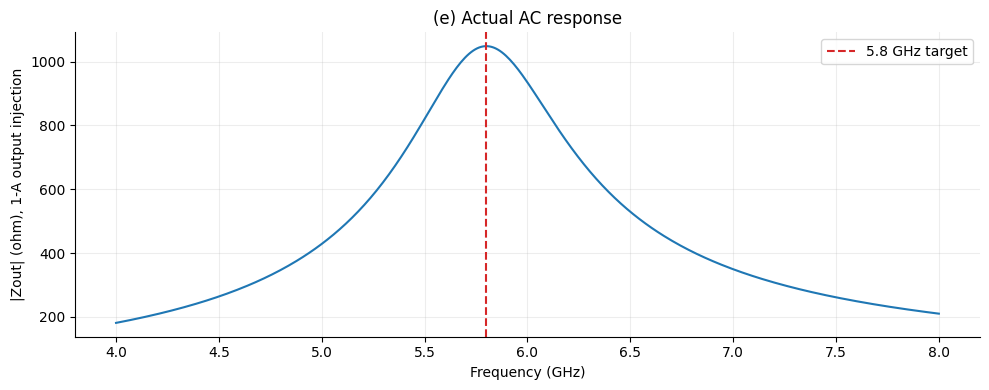

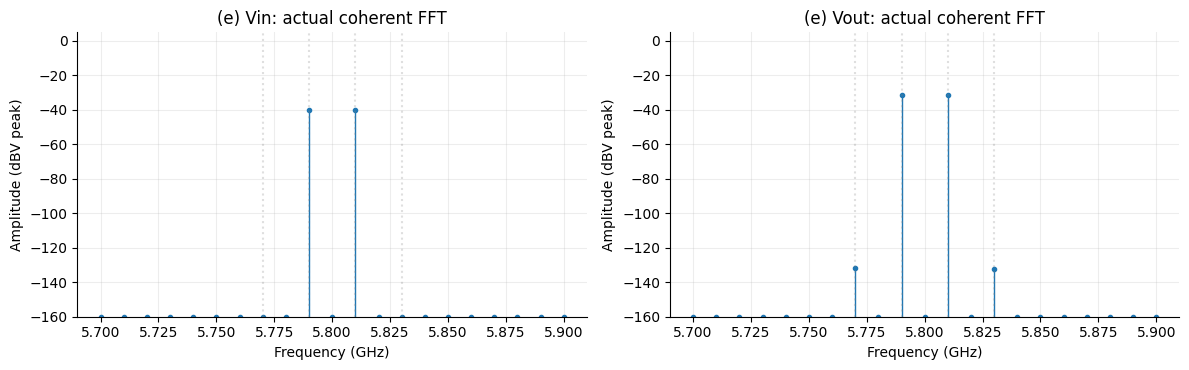

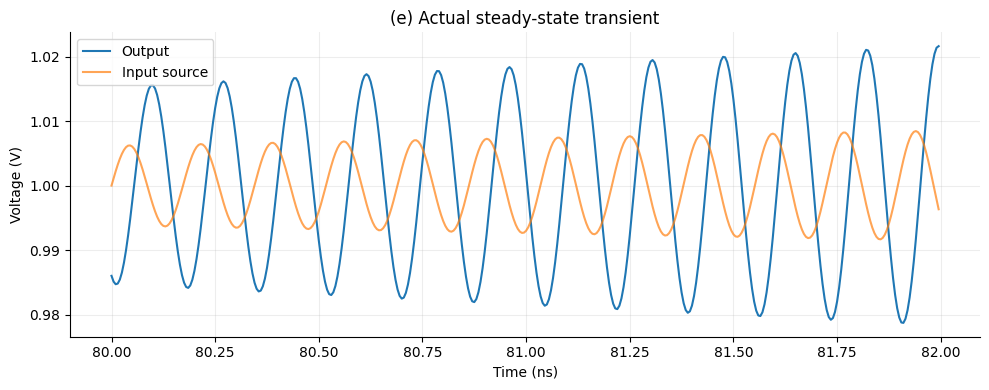

| IIP3 method | Samples | IIP3 (dBV peak) |
|---|---|---|
| Preserved submission projection | 19999 | -1.7533 |
| Exact coherent-window check | 20000 | 10.3137 |

The original window selected **19999** samples; the coherent check uses **20000** samples over exactly 100 ns. Coherent minus legacy IIP3: **+12.067 dB**. Original submission metrics remain above. The coherent single-point estimate also needs an amplitude sweep before treating it as a validated intercept.

In [7]:
if EXECUTION_MODE == "review":
    show_part("e")